In [4]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiLineString, LineString
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys

In [ ]:
# Add project root to sys.path
PROJECT_ROOT = Path.cwd().parent

# Set a site name
SITE_NAME = "salinas"

SDW_FOLDER = PROJECT_ROOT / "results" / "sdw_exports"
RWL_FOLDER = PROJECT_ROOT / "data" / "images" / SITE_NAME / "reference_wl"

In [6]:
# Load the SDW shapefile
sdw = gpd.read_file(SDW_FOLDER / f"sdw_{SITE_NAME}.shp")

# Load the RWL shapefile
rwl = gpd.read_file(RWL_FOLDER / f"{SITE_NAME}_wl_agj.shp")

In [7]:
# Get unique dates from RWL
rwl_dates = rwl['date'].unique()

# Filter SDW to only include lines that intersect with RWL dates
sdw_filtered = sdw[sdw['date'].isin(rwl_dates)]

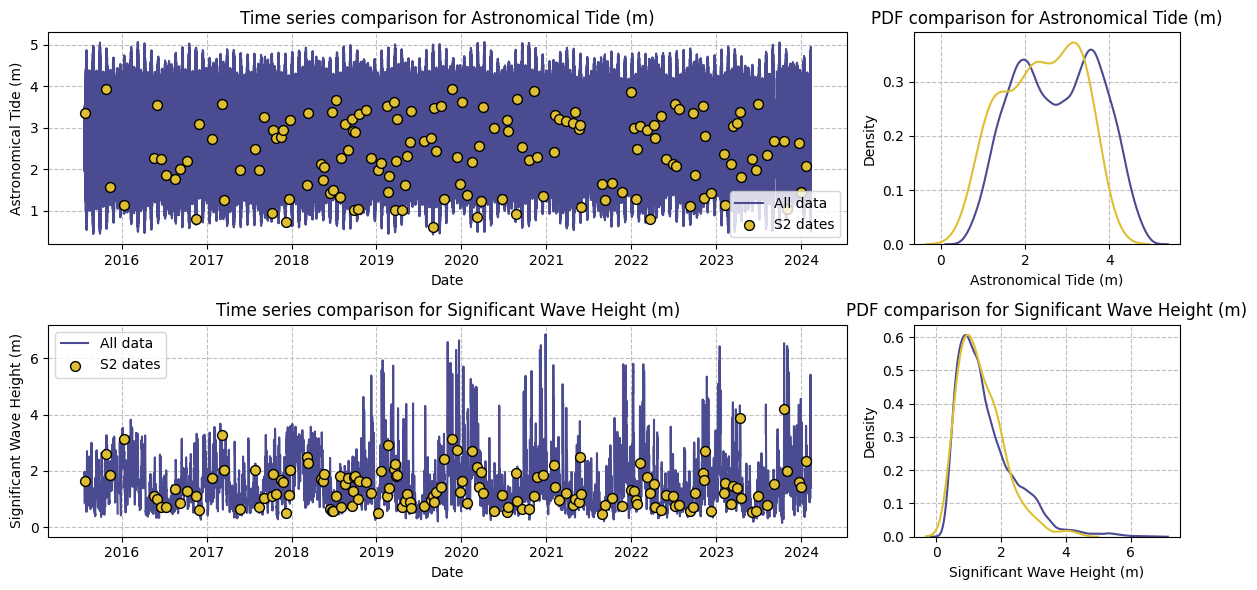

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load the marine data CSV
marine_data = pd.read_csv(PROJECT_ROOT / "data" / "marine_data"/ SITE_NAME / "marine_data.csv")
# Convert 'date' column to datetime
marine_data['date'] = pd.to_datetime(marine_data['date'])
# Crop marine data to the date range of RWL
marine_data = marine_data[
    (marine_data['date'] >= rwl['date'].min()) & 
    (marine_data['date'] <= rwl['date'].max())
    ]

rwl['date_hour'] = pd.to_datetime(rwl['date']) + pd.Timedelta(hours=11)  # Add 11 hours to get the timestamp for the SDW lines

# Intersect rwl dates with marine_data dates
rwl_dates = rwl.merge(marine_data, left_on='date_hour', right_on='date', how='inner')

fig, ax = plt.subplots(2, 2, figsize=(12, 6), width_ratios=[3, 1])

for i, var in enumerate(['tide', 'hs']):

    var_label = 'Astronomical Tide (m)' if var == 'tide' else 'Significant Wave Height (m)'

    # ax[i, 0] -> Tide/hs time series
    ax[i, 0].plot(marine_data['date'], marine_data[var], label='All data', color='#4B4B91')
    ax[i, 0].scatter(rwl_dates['date_hour'], rwl_dates[var],
            label='S2 dates', s=50,
            color='#DEBF33', edgecolor='k', zorder=2)
    ax[i, 0].set_xlabel('Date')
    ax[i, 0].set_ylabel(var_label)
    ax[i, 0].set_title(f'Time series comparison for {var_label}')
    ax[i, 0].grid(alpha=.8, ls='--')
    ax[i, 0].legend()

    # ax[i, 1] -> Tide PDF
    sns.kdeplot(
        data=marine_data,
        x=var,
        color='#4B4B91',
        ax=ax[i, 1]
    )
    sns.kdeplot(
        data=rwl_dates,
        x=var,
        color='#DEBF33',
        ax=ax[i, 1]
    )
    ax[i, 1].grid(alpha=.8, ls='--')
    ax[i, 1].set_title(f'PDF comparison for {var_label}')
    ax[i, 1].set_xlabel(var_label)

plt.tight_layout()
fig.savefig(PROJECT_ROOT / "data" / "marine_data"/ SITE_NAME / "marine_data_comparison.png", dpi=300)

In [57]:
# Reproject to ETRS89 (UTM zone 30N)
sdw_filtered = sdw_filtered.to_crs(epsg=25830)

# Filter out to only include efficientnet-b7 lines and segformer efficientnet-b4 lines
sdw_filtered = sdw_filtered[(sdw_filtered['encoder'] == 'efficientnet-b7') | (sdw_filtered['model_name'] == 'segformer_efficientnet-b4')]

In [58]:
# Export the filtered SDW to a new shapefile
output_path = SDW_FOLDER / f"sdw_{SITE_NAME}_filtered_new.shp"
sdw_filtered.to_file(output_path)
print(f"Filtered SDW exported to: {output_path}")

Filtered SDW exported to: /Users/albert/Documents/GitHub/sentinel2-coastline-benchmarking/results/sdw_exports/sdw_salinas_filtered_new.shp
